# 어뷰저 탐지 및 지표 영향 분석
### 데이터 개요
- **데이터 배경**: 가상 MMORPG **Astrasia Online** 서비스 데이터

- **데이터 기간**: 2026-07-01 ~ 2026-09-28 (90일)

- **분석 대상 테이블**
  - `users.csv`: 유저 정보
  - `daily_activity.csv`: 일별 접속, 플레이타임, 골드, 아이템
  - `funnel_events.csv`: 성장 퍼널 이벤트
  - `payments.csv`: 결제 내역
  
- **분석 대상 유저 수:** 데이터 기간 중 접속일 **7일 이상** 유저 8,543 명
    - 분석 기간 접속 유저 18,401명 중 46.4%가 해당됨.
    - 일별 획득량의 변동계수를 안정적으로 계산하려면 최소한의 일별 관측값이 필요하여 기준을 설정함.

## 1. 환경설정 및 데이터 확인

In [1]:
# 환경 설정
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# csv 파일 불러오기
users = pd.read_csv("../data/users.csv", parse_dates=["signup_date"])
daily = pd.read_csv("../data/daily_activity.csv", parse_dates=["date"])
events = pd.read_csv("../data/funnel_events.csv", parse_dates=["event_time"])
payments = pd.read_csv("../data/payments.csv", parse_dates=["paid_at"])

In [2]:
# 관측 기간 중 접속일 7일 이상 유저 비율

# 유저별 접속일 수
active_days = daily.groupby("user_id")["date"].nunique()
is_target = active_days >= 7

# 접속 유저 수, 분석 대상(7일 이상), 제외(7일 미만)
n_active = len(active_days)
n_target = is_target.sum()
n_excluded = n_active - n_target

target_pct = n_target / n_active * 100
excluded_pct = n_excluded / n_active * 100

# 제외 유저의 플레이타임 비중
excluded_ids = active_days[~is_target].index
excluded_playtime = daily.loc[daily["user_id"].isin(excluded_ids), "playtime_min"].sum()
total_playtime = daily["playtime_min"].sum()
excluded_playtime_pct = excluded_playtime / total_playtime * 100

print(f"기간 중 접속 유저: {n_active:,}명")
print(f"접속일 7일 이상 (분석 대상): {n_target:,}명 ({target_pct:.1f}%)")
print(f"접속일 7일 미만 (제외): {n_excluded:,}명 ({excluded_pct:.1f}%)")
print(f"제외 유저의 플레이타임 비중: {excluded_playtime_pct:.1f}%")

기간 중 접속 유저: 18,401명
접속일 7일 이상 (분석 대상): 8,543명 (46.4%)
접속일 7일 미만 (제외): 9,858명 (53.6%)
제외 유저의 플레이타임 비중: 3.3%


## 2. 어뷰징 판단 기준 탐색
- 플레이타임, 튜토리얼 완료 후 first_dungeon 이벤트 달성(첫 던전 클리어)까지 걸린 시간, 시간당 골드·아이템 획득량, 일별 골드·아이템 획득량의 분포 확인
- **골드 및 아이템 변동계수(CV)**: 일별 획득량의 표준편차 ÷ 평균.
    - 값이 낮을수록 매일 비슷한 양을 획득한다는 뜻으로, 정상적인 게임 활동보다는 골드·아이템 수집용 계정일 가능성이 있다고 판단함.

In [3]:
# 유저별 기본 지표
acct = (daily.groupby("user_id")
    .agg(active_days=("date", "nunique"),
         avg_playtime_min=("playtime_min", "mean"),
         total_playtime=("playtime_min", "sum"),
         total_gold=("gold_earned", "sum"),
         total_items=("items_acquired", "sum"),
         gold_mean=("gold_earned", "mean"),
         gold_std=("gold_earned", "std"),
         item_mean=("items_acquired", "mean"),
         item_std=("items_acquired", "std"))
    .reset_index())

acct["gold_per_hour"] = acct["total_gold"] / (acct["total_playtime"] / 60)
acct["items_per_hour"] = acct["total_items"] / (acct["total_playtime"] / 60)
acct["gold_cv"] = acct["gold_std"] / acct["gold_mean"]
acct["item_cv"] = acct["item_std"] / acct["item_mean"]

# 튜토리얼 후 first_dungeon 달성까지 시간
event_times = (events[events["event"]
                      .isin(["tutorial_complete", "first_dungeon"])]
                      .pivot_table(index="user_id",
                                   columns="event",
                                   values="event_time",
                                   aggfunc="min"))
event_times["tut_to_dungeon_hrs"] = (event_times["first_dungeon"] - event_times["tutorial_complete"]).dt.total_seconds() / 3600
acct = acct.merge(event_times[["tut_to_dungeon_hrs"]].reset_index(), on="user_id", how="left")

# 접속일 7일 미만 제외
acct = acct[acct["active_days"] >= 7].reset_index(drop=True)
acct = acct.drop(columns=["total_playtime", "total_gold", "total_items",
                          "gold_mean", "gold_std", "item_mean", "item_std"])

print(f"접속일 7일 이상 유저 수: {len(acct):,}명")
acct.head()

접속일 7일 이상 유저 수: 8,543명


,user_id,active_days,avg_playtime_min,gold_per_hour,items_per_hour,gold_cv,item_cv,tut_to_dungeon_hrs
0,4,86,391.936047,14803.405278,29.584798,0.173987,0.244106,NaN
1,6,32,141.346875,11853.246667,9.046893,0.644048,0.587546,NaN
2,8,36,151.216667,11137.539954,8.530806,0.504252,0.630375,NaN
3,40,19,59.736842,9363.859031,5.180617,0.774742,0.699821,NaN
4,47,34,140.467647,13046.793275,10.753994,0.663920,0.885812,NaN


In [4]:
acct.describe()

,user_id,active_days,avg_playtime_min,gold_per_hour,items_per_hour,gold_cv,item_cv,tut_to_dungeon_hrs
count,8543.000000,8543.000000,8543.000000,8543.000000,8543.000000,8543.000000,8543.000000,1243.000000
mean,19740.489172,28.463537,162.408401,11306.581501,9.172657,0.640579,0.691066,123.331917
std,8253.293269,21.457653,180.621075,3322.772795,4.753260,0.207294,0.214953,154.547227
min,4.000000,7.000000,30.762500,217.839614,0.516307,0.034443,0.030111,3.588889
25%,13946.000000,11.000000,66.010000,9236.253643,6.606535,0.546240,0.583906,38.836806
50%,21240.000000,21.000000,147.226744,11396.294789,8.552925,0.631886,0.674302,69.268889
75%,26337.500000,40.000000,160.626136,13179.406847,9.918109,0.734489,0.795662,145.175000
max,33627.000000,90.000000,1267.784444,30977.649535,49.076694,4.553877,2.009791,1611.208889


* 하루 평균 플레이타임과 시간당 아이템 획득량은 오른쪽으로 긴 꼬리를 가진 분포임.  
* 특이사항은 보이지 않아 신호 1~3은 이상치 판단의 표준 방법인 IQR 상한(Q3 + 1.5×IQR)을 기준으로 사용함.

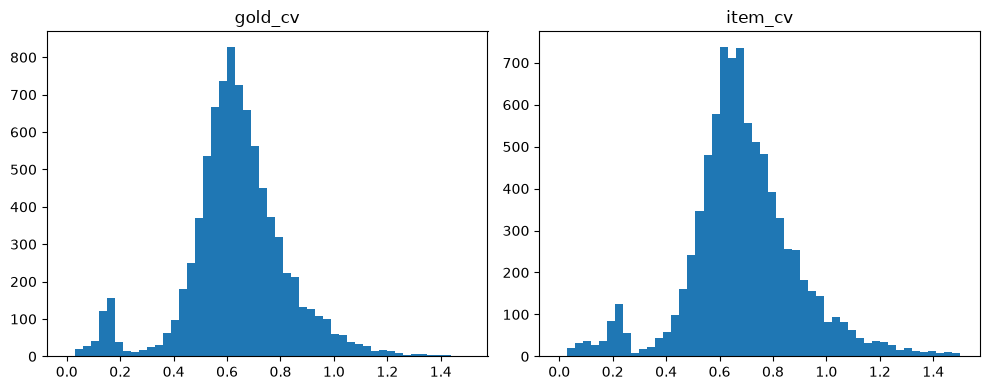

In [5]:
# cv 히스토그램
# cv: coefficient of variation(변동계수)= 표준편차 / 평균
# 변동이 없을 경우 cv는 0, 변동이 커질수록 값이 커짐

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# gold cv
axes[0].hist(acct["gold_cv"].dropna(), bins=50, range=(0, 1.5))
axes[0].set_title("gold_cv")

# item cv
axes[1].hist(acct["item_cv"].dropna(), bins=50, range=(0, 1.5))
axes[1].set_title("item_cv")

plt.tight_layout()
plt.show()

In [6]:
# 0.0 ~ 0.5 사이의 유저 수 분포
# 0.05 단위
# (: 이상, ]: 이하

bins = np.arange(0, 0.55, 0.05)

cv_counts = pd.DataFrame({
    "gold_cv": pd.cut(acct["gold_cv"], bins, include_lowest=True).value_counts().sort_index(),
    "item_cv": pd.cut(acct["item_cv"], bins, include_lowest=True).value_counts().sort_index(),
})

cv_counts

,gold_cv,item_cv
"(-0.001, 0.05]",12,13
"(0.05, 0.1]",46,49
"(0.1, 0.15]",150,54
"(0.15, 0.2]",186,94
"(0.2, 0.25]",30,178
"(0.25, 0.3]",23,38
"(0.3, 0.35]",50,33
"(0.35, 0.4]",99,68
"(0.4, 0.45]",245,139
"(0.45, 0.5]",486,312


* 골드와 아이템 변동계수 분포 모두 낮은 쪽에 작은 봉우리가 있고, 유저 수가 줄었다가 다시 늘어나는 저점이 있음.  
  이 저점을 기준으로 **골드 0.3 미만, 아이템 0.35 미만**을 규칙적 획득 패턴으로 지정함.  
* 어뷰징 계정이 골드 또는 아이템 중 한 쪽의 획득에만 치중할 수 있으므로, 두 조건을 별도의 조건으로 두기보다 하나의 조건으로 통합하여 보기로 함.

## 3. 어뷰징 의심 계정 판정 기준
규칙 기반 탐지  
**확정 판정이 아닌 의심 계정 선별 목적**입니다.

### 신호별 기준

| # | 신호 | 지표 | 기준 | 근거 |
|---|---|---|---|---|
| 1 | 장시간 플레이 | 하루 평균 플레이타임 (`avg_playtime_min`) | IQR 상한 (Q3 + 1.5×IQR) 초과 | |
| 2 | 빠른 골드 획득 | 시간당 골드 (`gold_per_hour`) | IQR 상한 (Q3 + 1.5×IQR) 초과 | |
| 3 | 빠른 아이템 획득 | 시간당 아이템 (`items_per_hour`) | IQR 상한 (Q3 + 1.5×IQR) 초과 | |
| 4 | 규칙적인 골드 또는 아이템 획득 패턴 | 일별 획득량 변동계수 (`gold_cv`, `item_cv`) | gold_cv < 0.3 또는 item_cv < 0.35 | 유저수 분포에서 낮아졌다가 높아지는 가장 낮은 지점 |
| 5 | 빠른 성장 속도 | 튜토리얼→첫 던전 시간 (`tut_to_dungeon_hrs`) | 1.7시간 미만 | 게임 설계상 Lv10 도달 최소 시간보다 빠르게 던전을 돌파한 경우 | 
- **다계정 기기는 판정 신호에서 제외함**: 한 기기를 가족, PC방 등 여러 사람이 공용으로 쓰는 경우가 있어, 엄격하게 잡으면 정상 유저까지 제재해 이탈을 유발할 수 있음.
- `빠른 성장 속도` 신호의 경우, 이번 데이터에서의 최솟값은 3.6시간으로, 해당되는 유저는 없었지만, 매크로 등으로 비정상적으로 빠르게 성장하는 계정을 탐지하기 위해 기준을 유지함.

### 판정 등급

| 해당 신호 수 | 등급 | 의미 |
|---|---|---|
| 0~1개 | normal | 정상 범위 (헤비 유저 포함) |
| 2개 | suspected | 어뷰징 의심 |
| 3개 이상 | highly_suspected | 어뷰징 고의심 |

In [7]:
# 신호 1~3 기준값 계산 함수: IQR 상한 = Q3 + 1.5 × IQR
def upper_fence(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return q3 + 1.5 * (q3 - q1)

playtime_threshold  = upper_fence(acct["avg_playtime_min"])
gold_threshold = upper_fence(acct["gold_per_hour"])
item_threshold = upper_fence(acct["items_per_hour"])

print(f"플레이타임 IQR 상한: {playtime_threshold:.1f}분")
print(f"골드 획득 IQR 상한: {gold_threshold:,.1f}골드/시간")
print(f"아이템 획득 IQR 상한: {item_threshold:.1f}개/시간")

플레이타임 IQR 상한: 302.6분
골드 획득 IQR 상한: 19,094.1골드/시간
아이템 획득 IQR 상한: 14.9개/시간


In [8]:
# 신호 4~5 기준값
gold_cv_threshold = 0.3         # gold_cv 히스토그램의 저점
item_cv_threshold = 0.35        # item_cv 히스토그램의 저점
fast_dungeon_threshold = 1.7    # 설계상 Lv10 도달 최소 시간(시간)

# 신호 1~3: IQR 상한 초과
acct["flag_playtime"] = acct["avg_playtime_min"] > playtime_threshold
acct["flag_gold_speed"] = acct["gold_per_hour"] > gold_threshold
acct["flag_item_speed"] = acct["items_per_hour"] > item_threshold

# 신호 4: 골드 또는 아이템 획득 패턴 변동계수가 기준점 미만(변동이 낮은 경우)
acct["flag_regular"] = (acct["gold_cv"] < gold_cv_threshold) | (acct["item_cv"] < item_cv_threshold)

# 신호 5: 설계상 레벨 10 도달 시간보다 빠른 경우
acct["flag_fast_growth"] = acct["tut_to_dungeon_hrs"] < fast_dungeon_threshold

acct.head()

,user_id,active_days,avg_playtime_min,gold_per_hour,items_per_hour,gold_cv,item_cv,tut_to_dungeon_hrs,flag_playtime,flag_gold_speed,flag_item_speed,flag_regular,flag_fast_growth
0,4,86,391.936047,14803.405278,29.584798,0.173987,0.244106,NaN,True,False,True,True,False
1,6,32,141.346875,11853.246667,9.046893,0.644048,0.587546,NaN,False,False,False,False,False
2,8,36,151.216667,11137.539954,8.530806,0.504252,0.630375,NaN,False,False,False,False,False
3,40,19,59.736842,9363.859031,5.180617,0.774742,0.699821,NaN,False,False,False,False,False
4,47,34,140.467647,13046.793275,10.753994,0.663920,0.885812,NaN,False,False,False,False,False


In [9]:
# 판정 등급별 유저 수
flag_cols = [c for c in acct.columns if c.startswith("flag_")]
acct["n_signals"] = acct[flag_cols].sum(axis=1)

acct["risk"] = pd.cut(acct["n_signals"], bins=[-1, 1, 2, 5],
                      labels=["normal", "suspected", "highly_suspected"])

risk_counts = acct["risk"].value_counts().sort_index().reset_index()
risk_counts.columns = ["risk", "accounts"]
risk_counts["pct"] = (risk_counts["accounts"] / risk_counts["accounts"].sum() * 100).round(1)

risk_counts

,risk,accounts,pct
0,normal,8116,95.0
1,suspected,37,0.4
2,highly_suspected,390,4.6


In [10]:
# 신호별 기준에 해당하는 유저 수
acct[flag_cols].sum().to_frame("accounts")

,accounts
flag_playtime,525
flag_gold_speed,115
flag_item_speed,412
flag_regular,489
flag_fast_growth,0


In [11]:
# 판정 등급별 지표 평균
acct.groupby("risk", observed=True)[["avg_playtime_min", "gold_per_hour",
                                     "items_per_hour", "gold_cv", "item_cv"]].mean().round(2)

,avg_playtime_min,gold_per_hour,items_per_hour,gold_cv,item_cv
risk,,,,,
normal,131.90,11316.08,8.28,0.67,0.72
suspected,1122.35,3364.65,11.87,0.30,0.21
highly_suspected,706.26,11862.37,27.57,0.14,0.18


- **판정 결과**: 분석 대상 8,543명 중 어뷰징 의심 37명(0.4%), 고의심 390명(4.6%)으로 **총 427명(5.0%)** 을 의심 계정으로 선별함.
- **신호별 해당 유저**: 장시간 플레이 525명, 규칙적 획득 489명, 빠른 아이템 획득 412명, 빠른 골드 획득 115명, 빠른 성장 0명.

## 4. 어뷰저 의심 계정 csv로 내보내기
프로모션 효과 분석에서 의심 계정을 제외하고 분석할 수 있도록 어뷰저 유저 목록을 csv로 내보내기

In [12]:
# suspected, highly_suspected 유저 추출
suspects = acct[acct["risk"] != "normal"][["user_id", "risk", "n_signals"] + flag_cols]

suspects.head()

,user_id,risk,n_signals,flag_playtime,flag_gold_speed,flag_item_speed,flag_regular,flag_fast_growth
0,4,highly_suspected,3,True,False,True,True,False
25,335,highly_suspected,3,True,False,True,True,False
30,369,highly_suspected,3,True,False,True,True,False
82,900,highly_suspected,3,True,False,True,True,False
147,1558,highly_suspected,3,True,False,True,True,False


In [13]:
# csv로 내보내기
suspects.to_csv("../output/abuser_analysis/abuser_suspect_list.csv", index=False)

print(f"✅저장 완료: {len(suspects):,}개 계정")

✅저장 완료: 427개 계정


## 5. 어뷰저 제외 전후 지표 비교

In [14]:
# 어뷰저 제외 일별 활동 데이터
abuser_ids = acct.loc[acct["risk"] != "normal", "user_id"]    # suspected + highly_suspected
daily_clean = daily[~daily["user_id"].isin(abuser_ids)]
payments_clean = payments[~payments["user_id"].isin(abuser_ids)]

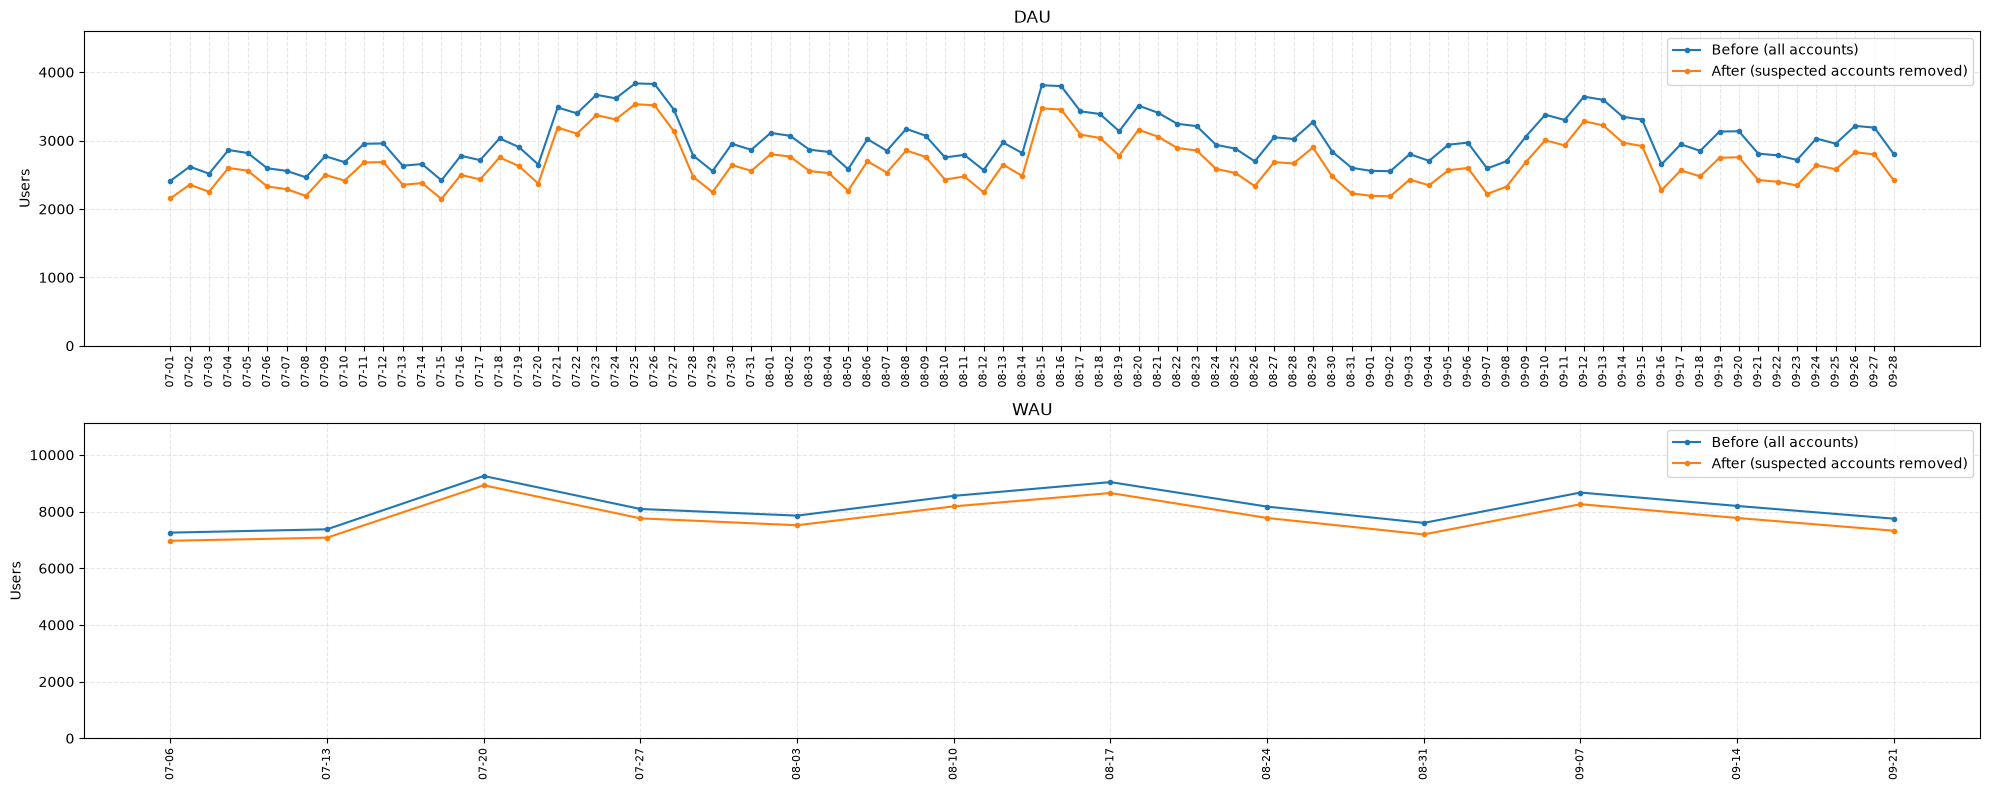

In [15]:
# DAU, WAU

def make_dau_wau(df):
    dau = df.groupby("date")["user_id"].nunique().reset_index(name="dau")
    week = (df["date"] - pd.to_timedelta(df["date"].dt.weekday, unit="D")).rename("week")
    wau = df.groupby(week).agg(wau=("user_id", "nunique"), days=("date", "nunique")).reset_index()
    wau = wau[wau["days"] == 7].drop(columns="days")     # 7일이 다 채워진 주만
    return dau, wau

dau_before, wau_before = make_dau_wau(daily)
dau_after, wau_after = make_dau_wau(daily_clean)

# (데이터, x축 컬럼, y축 컬럼, 그래프 제목)
charts = [
    ((dau_before, dau_after), "date", "dau", "DAU"),
    ((wau_before, wau_after), "week", "wau", "WAU"),
]

# (범례 이름, 색상)
compare_styles = [("Before (all accounts)", "C0"), ("After (suspected accounts removed)", "C1")]

fig, axes = plt.subplots(2, 1, figsize=(20, 8))

for ax, (data_pair, x_col, y_col, title) in zip(axes, charts):
    for t, (label, color) in zip(data_pair, compare_styles):
        ax.plot(t[x_col], t[y_col], marker="o", markersize=3, color=color, label=label)

    # y축을 0부터 시작 (제외 전후 중 큰 값 기준)
    y_max = data_pair[0][y_col].max()
    ax.set_ylim(0, y_max * 1.2)

    ax.set_title(title)
    ax.set_ylabel("Users")
    ax.legend()
    ax.grid(alpha=0.3, linestyle="--")

    # x축: DAU는 일자별, WAU는 주(월요일)별 눈금
    x_values = data_pair[0][x_col]
    ax.set_xticks(x_values)
    ax.set_xticklabels(x_values.dt.strftime("%m-%d"), rotation=90, fontsize=8)

plt.tight_layout()
plt.show()

어뷰저 의심, 고의심 계정을 제외하면 DAU와 WAU는 낮아지지만 증감 패턴은 그대로 유지됨.  
어뷰저 유저의 경우 기간과 관계없이 비교적 일정하게 접속하기 때문으로 보임.

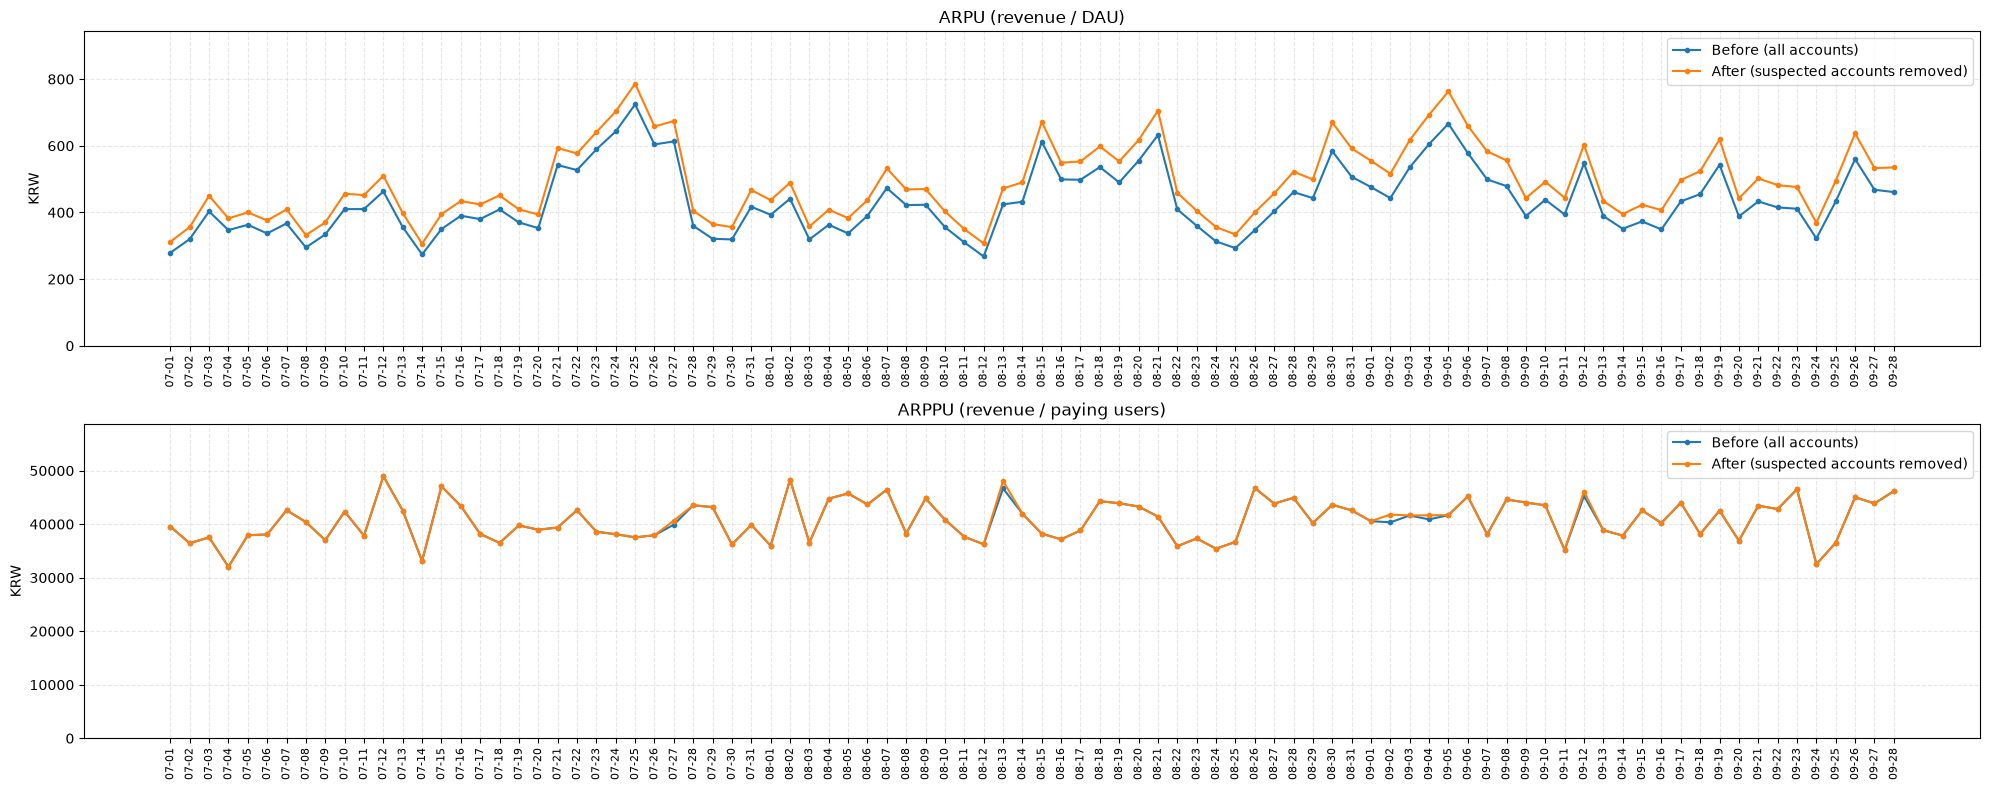

In [16]:
# ARPU, ARPPU

def make_arpu_daily(dau_df, pay_df):
    # 일별 결제 유저 수, 매출
    pay_date = pay_df["paid_at"].dt.normalize().rename("date")
    daily_pay = pay_df.groupby(pay_date).agg(payers=("user_id", "nunique"),
                                             revenue=("amount_krw", "sum")).reset_index()

    # DAU 표에 붙이기 (결제가 없는 날은 0)
    t = dau_df.merge(daily_pay, on="date", how="left")
    t[["payers", "revenue"]] = t[["payers", "revenue"]].fillna(0)
    t["arpu"] = (t["revenue"] / t["dau"]).round(0)          # 접속 유저 1명당 매출
    t["arppu"] = (t["revenue"] / t["payers"]).round(0)      # 결제 유저 1명당 매출
    return t

arpu_before = make_arpu_daily(dau_before, payments)
arpu_after = make_arpu_daily(dau_after, payments_clean)

# (지표, 그래프 제목)
metrics = [("arpu", "ARPU (revenue / DAU)"), ("arppu", "ARPPU (revenue / paying users)")]

# (데이터, 범례 이름, 색상)
compare_sets = [
    (arpu_before, "Before (all accounts)", "C0"),
    (arpu_after, "After (suspected accounts removed)", "C1"),
]

fig, axes = plt.subplots(2, 1, figsize=(20, 8))

for ax, (name, title) in zip(axes, metrics):
    for t, label, color in compare_sets:
        ax.plot(t["date"], t[name], marker="o", markersize=3, color=color, label=label)

    # y축을 0부터 시작 (제외 전후 중 큰 값 기준)
    y_max = max(arpu_before[name].max(), arpu_after[name].max())
    ax.set_ylim(0, y_max * 1.2)

    ax.set_title(title)
    ax.set_ylabel("KRW")
    ax.legend()
    ax.grid(alpha=0.3, linestyle="--")

    # x축: 일자별 눈금, 90도 회전
    ax.set_xticks(arpu_before["date"])
    ax.set_xticklabels(arpu_before["date"].dt.strftime("%m-%d"), rotation=90, fontsize=8)

plt.tight_layout()
plt.show()

어뷰저 의심, 고의심 계정을 제외하면 ARPU는 패턴을 유지한 채 소폭 높아지고, ARPPU는 대부분의 일자에서 거의 변하지 않음.  
매출은 비슷한데 분모인 DAU만 줄어든 결과로 보이며, 의심 계정의 매출 기여는 낮은 것을 확인함.

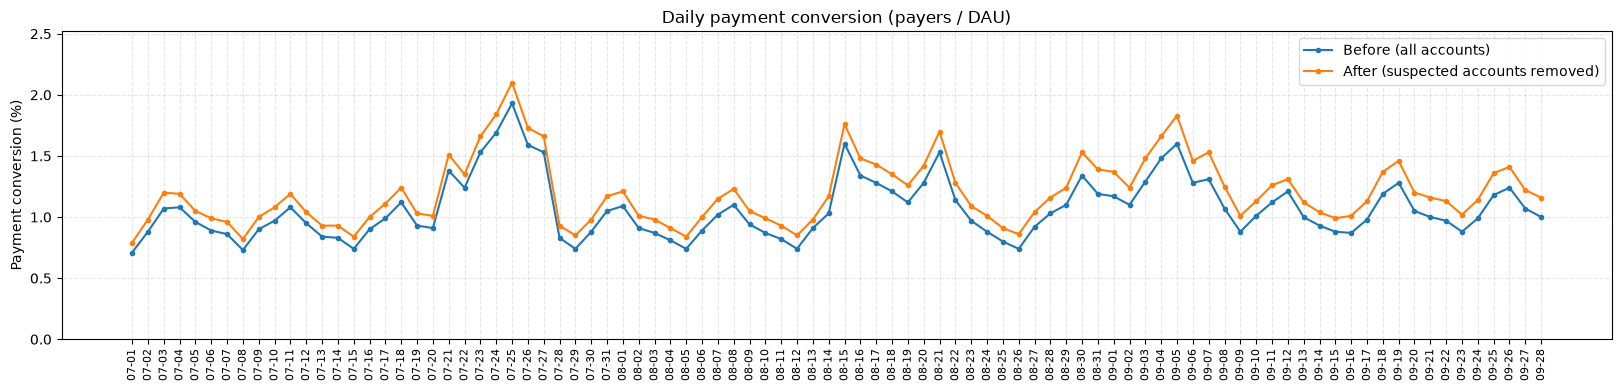

In [17]:
# 결제 전환율

def make_pay_conv_daily(dau_df, pay_df):
    # 일별 결제 유저 수
    pay_date = pay_df["paid_at"].dt.normalize().rename("date")
    payers = pay_df.groupby(pay_date)["user_id"].nunique().reset_index(name="payers")

    # DAU 표에 붙여서 전환율 계산 (결제가 없는 날은 0명)
    conv = dau_df.merge(payers, on="date", how="left")
    conv["payers"] = conv["payers"].fillna(0)
    conv["pay_conv_pct"] = (conv["payers"] / conv["dau"] * 100).round(2)
    return conv

pay_conv_before = make_pay_conv_daily(dau_before, payments)
pay_conv_after = make_pay_conv_daily(dau_after, payments_clean)

# (데이터, 범례 이름, 색상)
compare_sets = [
    (pay_conv_before, "Before (all accounts)", "C0"),
    (pay_conv_after, "After (suspected accounts removed)", "C1"),
]

fig, ax = plt.subplots(figsize=(20, 4))

for conv, label, color in compare_sets:
    ax.plot(conv["date"], conv["pay_conv_pct"], marker="o", markersize=3, color=color, label=label)

# y축을 0부터 시작 (제외 전후 중 큰 값 기준)
y_max = max(pay_conv_before["pay_conv_pct"].max(), pay_conv_after["pay_conv_pct"].max())
ax.set_ylim(0, y_max * 1.2)

ax.set_title("Daily payment conversion (payers / DAU)")
ax.set_ylabel("Payment conversion (%)")
ax.legend()
ax.grid(alpha=0.3, linestyle="--")

# x축: 일자별 눈금, 90도 회전
ax.set_xticks(pay_conv_before["date"])
ax.set_xticklabels(pay_conv_before["date"].dt.strftime("%m-%d"), rotation=90, fontsize=8)

plt.show()

어뷰저 의심, 고의심 계정을 제외하면 결제 전환율이 소폭 높아짐.  
의심 계정은 일반 계정보다 적게 결제하거나, 결제하지 않기 때문에 제외할 경우 결제 전환율이 높아진 것으로 판단됨.

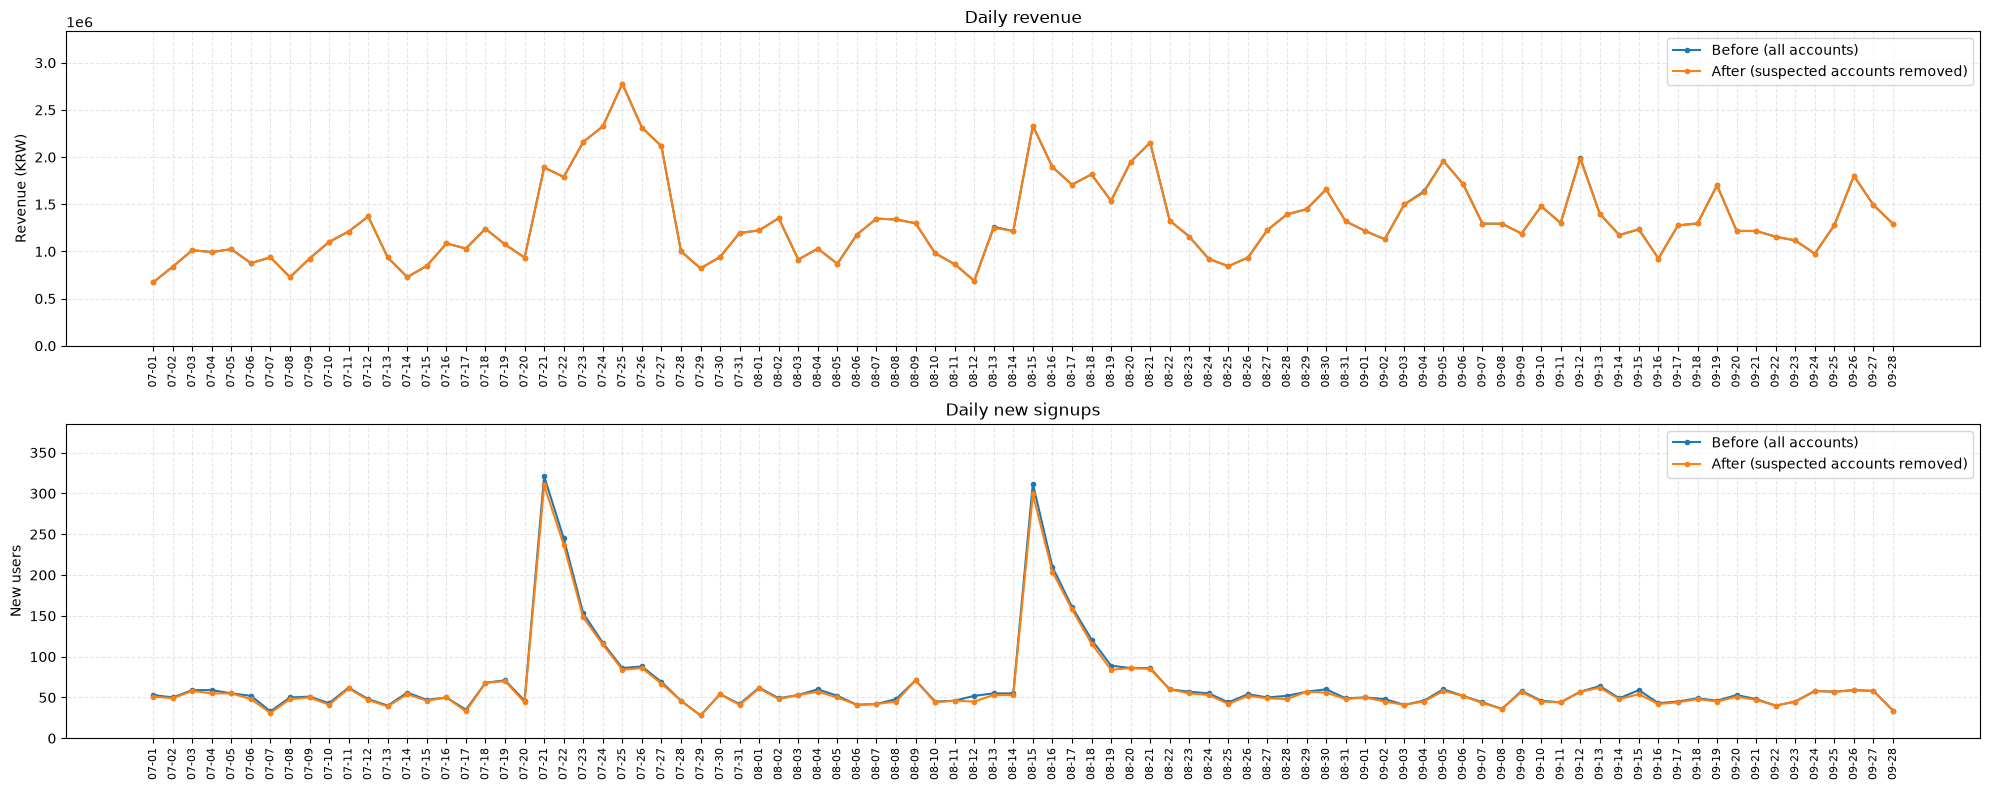

In [18]:
# 매출, 신규 가입자
obs_start = daily["date"].min()     # 데이터 시작일
obs_end = daily["date"].max()       # 데이터 종료일
all_dates = pd.date_range(obs_start, obs_end, freq="D")

# 신규 가입자 집계용 users (어뷰저 제외)
users_clean = users[~users["user_id"].isin(abuser_ids)]

def make_revenue_signups(pay_df, users_df):
    # 일별 매출 (결제가 없는 날은 0)
    pay_date = pay_df["paid_at"].dt.normalize()
    revenue = pay_df.groupby(pay_date)["amount_krw"].sum()
    revenue = revenue.reindex(all_dates, fill_value=0)

    # 일별 신규 가입자 (데이터 기간 내 가입)
    new_users = users_df[users_df["signup_date"] >= obs_start]
    signups = new_users.groupby("signup_date")["user_id"].nunique()
    signups = signups.reindex(all_dates, fill_value=0)

    return pd.DataFrame({"revenue": revenue, "signups": signups})

rev_before = make_revenue_signups(payments, users)
rev_after = make_revenue_signups(payments_clean, users_clean)

# (컬럼, 그래프 제목, y축 이름)
charts = [
    ("revenue", "Daily revenue", "Revenue (KRW)"),
    ("signups", "Daily new signups", "New users"),
]

# (데이터, 범례 이름, 색상)
compare_sets = [
    (rev_before, "Before (all accounts)", "C0"),
    (rev_after, "After (suspected accounts removed)", "C1"),
]

fig, axes = plt.subplots(2, 1, figsize=(20, 8))

for ax, (col, title, ylabel) in zip(axes, charts):
    for t, label, color in compare_sets:
        ax.plot(t.index, t[col], marker="o", markersize=3, color=color, label=label)

    # y축을 0부터 시작 (제외 전후 중 큰 값 기준)
    y_max = max(rev_before[col].max(), rev_after[col].max())
    ax.set_ylim(0, y_max * 1.2)

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(alpha=0.3, linestyle="--")

    # x축: 일자별 눈금, 90도 회전
    ax.set_xticks(all_dates)
    ax.set_xticklabels(all_dates.strftime("%m-%d"), rotation=90, fontsize=8)

plt.tight_layout()
plt.show()

어뷰저 의심, 고의심 계정을 제외하더라도 매출은 거의 동일했으며, 신규 유저 수는 일부 일자에서 소폭 감소함.

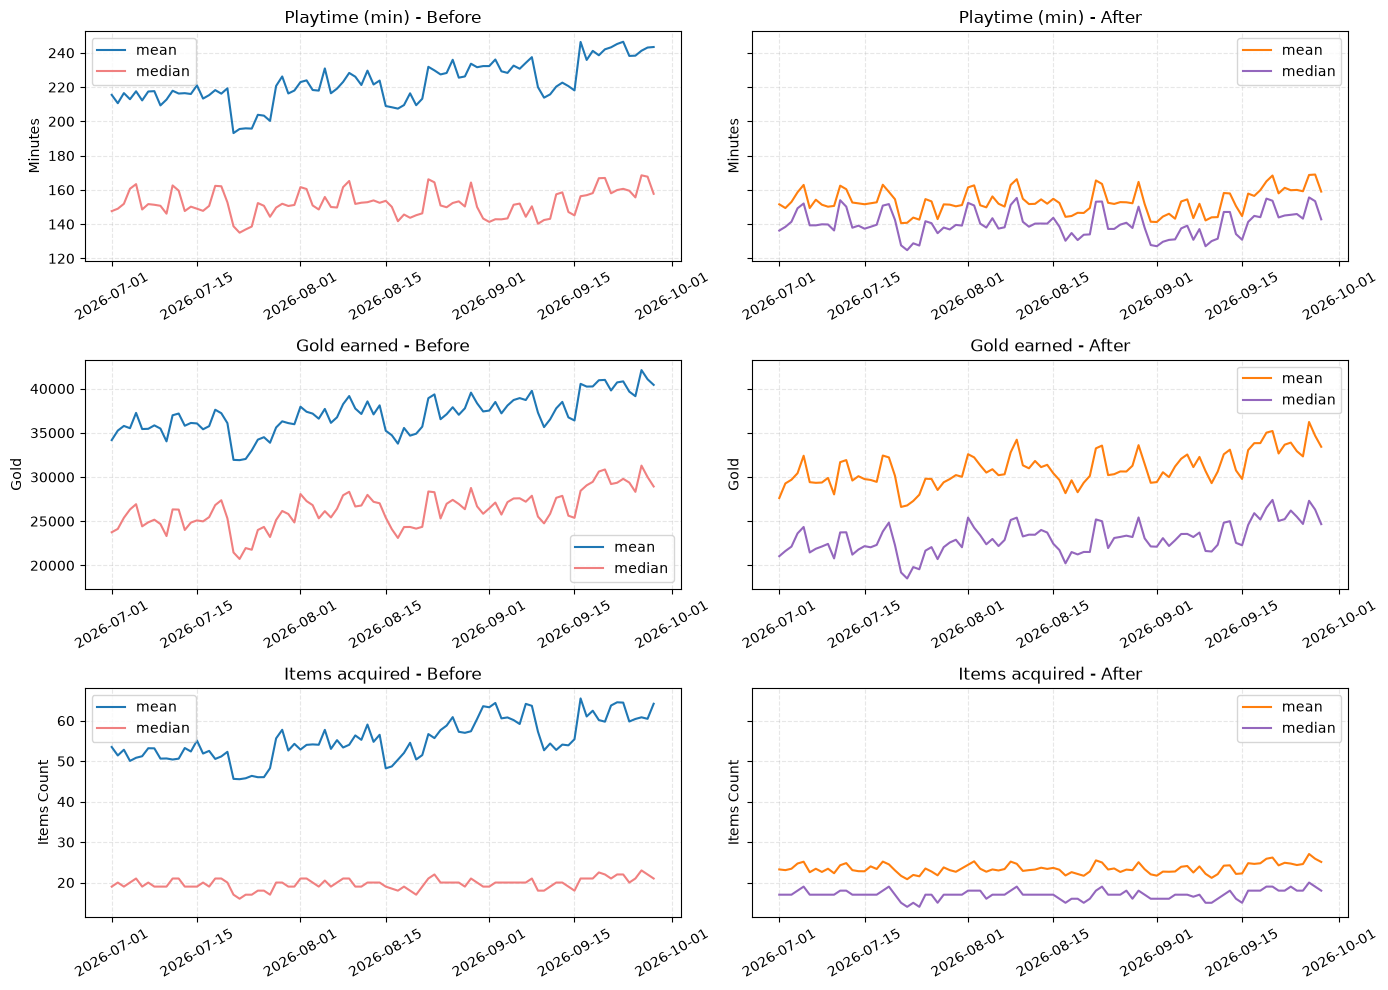

In [19]:
# 일별 플레이타임, 골드 획득량, 아이템 획득량 평균·중앙값 (어뷰저 제외 전후 비교)

def make_daily_stats(df):
    return (df.groupby("date")
        .agg(avg_playtime_min=("playtime_min", "mean"), median_playtime_min=("playtime_min", "median"),
             avg_gold=("gold_earned", "mean"), median_gold=("gold_earned", "median"),
             avg_items=("items_acquired", "mean"), median_items=("items_acquired", "median"))
        .reset_index())

stats_before = make_daily_stats(daily)
stats_after = make_daily_stats(daily_clean)

# (지표 이름, 그래프 제목, y축 이름)
metrics = [("playtime_min", "Playtime (min)", "Minutes"),
           ("gold", "Gold earned", "Gold"),
           ("items", "Items acquired", "Items Count")]

# (데이터, 제목 뒷부분, 평균 색, 중앙값 색)
# 제외 전: 평균 파랑, 중앙값 연빨강 / 제외 후: 평균 주황, 중앙값 보라
compare_sets = [(stats_before, "Before", "C0", "lightcoral"),
                (stats_after, "After", "C1", "C4")]

fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharey="row")

for row, (name, label, ylabel) in enumerate(metrics):
    for col, (stats, period, mean_color, median_color) in enumerate(compare_sets):
        ax = axes[row, col]
        ax.plot(stats["date"], stats[f"avg_{name}"], color=mean_color, label="mean")
        ax.plot(stats["date"], stats[f"median_{name}"], color=median_color, label="median")
        ax.set_title(f"{label} - {period}")
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3, linestyle="--")
        ax.legend()
        ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

- **플레이타임 · 아이템 획득량**: 의심 계정을 제외하면 평균과 중앙값의 차이가 크게 줄어듦. 소수의 의심 계정이 평균을 끌어올리고 있었던 것으로 보임.
- **골드 획득량**: 평균과 중앙값의 차이가 줄었지만, 플레이타임과 아이템보다는 차이가 크게 남음. 정상 유저 중에도 골드를 특히 많이 획득하는 유저가 있는 것으로 보임.
- 의심 계정은 골드보다 **아이템 획득에 치중**하는 경향이 있음.
    - 아이템 종류별 획득 로그가 있다면, **의심 계정이 주로 획득하는 아이템을 확인해 추가 탐지 신호로 활용**할 수 있음.
    - 대량으로 풀린 아이템은 경매장 시세에 영향을 줄 수 있어, **해당 아이템의 시세 모니터링이 필요**함.

In [20]:
# 기간 정의와 일별 지표 함수
# (obs_start, all_dates, users_clean은 위 매출·신규 가입자 셀에서 만든 것을 사용)

# 프로모션 및 업데이트 기간 (EDA와 동일)
periods = {
    "여름 축제 1부": ("2026-07-21", "2026-07-27"),
    "여름 축제 2부": ("2026-08-15", "2026-08-21"),
    "성장 개편 업데이트 이후 핫픽스 전": ("2026-08-30", "2026-09-07"),
    "핫픽스일": ("2026-09-08", "2026-09-08"),
    "복귀 지원 프로모션": ("2026-09-09", "2026-09-15"),
    "복귀 지원 프로모션 종료 후": ("2026-09-16", "2026-09-28"),
}

# 날짜별 구분 (어느 기간에도 속하지 않으면 "평시")
date_period = pd.Series("평시", index=all_dates)
for name, (start, end) in periods.items():
    in_period = (all_dates >= pd.Timestamp(start)) & (all_dates <= pd.Timestamp(end))
    date_period[in_period] = name

period_order = ["평시"] + list(periods.keys())


# 일별 지표 표: DAU, 신규 가입자, 매출, 플레이타임·골드·아이템 평균/중앙값
def make_daily_metrics(daily_df, pay_df, users_df):
    # DAU
    dau = daily_df.groupby("date")["user_id"].nunique()

    # 신규 가입자 (데이터 기간 내 가입)
    new_users = users_df[users_df["signup_date"] >= obs_start]
    signups = new_users.groupby("signup_date")["user_id"].nunique()
    signups = signups.reindex(all_dates, fill_value=0)

    # 매출
    pay_date = pay_df["paid_at"].dt.normalize()
    revenue = pay_df.groupby(pay_date)["amount_krw"].sum()
    revenue = revenue.reindex(all_dates, fill_value=0)

    # 플레이타임, 골드, 아이템 평균·중앙값 (위에서 만든 make_daily_stats 재사용)
    stats = make_daily_stats(daily_df).set_index("date")

    metrics = pd.DataFrame({"dau": dau, "signups": signups, "revenue": revenue})
    metrics = metrics.join(stats)
    return metrics


metrics_before = make_daily_metrics(daily, payments, users)
metrics_after = make_daily_metrics(daily_clean, payments_clean, users_clean)

In [21]:
# 전체 기간 지표 비교 (어뷰저 제외 전 vs 어뷰저 제외 후)

# DAU, 신규 가입자, 매출: 하루 단위 지표라 일평균
daily_cols = ["dau", "signups", "revenue"]
daily_mean_before = metrics_before[daily_cols].mean()
daily_mean_after = metrics_after[daily_cols].mean()

# 플레이타임, 골드, 아이템: 유저·일 기준 (전체 유저·일 기록에서 바로 평균·중앙값 계산)
activity_cols = {"playtime_min": "playtime_min", "gold_earned": "gold", "items_acquired": "items"}

def make_user_day_stats(df):
    stats = {}
    for col, name in activity_cols.items():
        stats[f"avg_{name}"] = df[col].mean()
        stats[f"median_{name}"] = df[col].median()
    return pd.Series(stats)

activity_before = make_user_day_stats(daily)
activity_after = make_user_day_stats(daily_clean)

# 두 기준을 한 표로 합치고 제외 전후 차이(%) 계산
level_before = pd.concat([daily_mean_before, activity_before])
level_after = pd.concat([daily_mean_after, activity_after])
level_diff = (level_after / level_before - 1) * 100

level_table = pd.DataFrame([level_before, level_after, level_diff],
                           index=["제외 전", "제외 후", "차이(%)"])

print("[전체 기간 지표: DAU·신규 가입자·매출은 일평균, 활동 지표는 유저·일 기준]")
display(level_table.round(1))

[전체 기간 지표: DAU·신규 가입자·매출은 일평균, 활동 지표는 유저·일 기준]


,dau,signups,revenue,avg_playtime_min,median_playtime_min,avg_gold,median_gold,avg_items,median_items
제외 전,2986.7,66.7,1314854.4,221.8,152.1,37011.9,26219.0,55.0,20.0
제외 후,2655.6,64.9,1314463.3,153.3,140.1,30942.1,23018.5,23.5,17.0
차이(%),-11.1,-2.7,-0.0,-30.9,-7.9,-16.4,-12.2,-57.3,-15.0


**⬆️ 표 계산 방식**
- **일평균 (DAU, 신규 가입자, 매출)**
    - 일평균 = (일별 값의 합) ÷ (전체 일수 90일)
    - 예: 일평균 DAU = (7/1 DAU + 7/2 DAU + … + 9/28 DAU) ÷ 90
- **유저 1인당 일평균 (플레이타임, 골드 획득량, 아이템 획득량)**
    - 유저 1인당 일평균 = (전체 기간 모든 유저의 일별 값 합) ÷ (유저별 접속일수의 합)
    - 예: 유저 1인당 일평균 플레이타임 = (모든 유저의 플레이타임 합) ÷ (유저별 접속일수의 합)

In [22]:
# 직전 평시 대비 프로모션·업데이트 기간 일평균 증감률 비교 (어뷰저 제외 전 vs 어뷰저 제외 후)
# 직전 평시: 비교 기간 직전의 프로모션·업데이트가 없는 날 중 동일 기간·동일 요일
# (핫픽스 전·핫픽스일·복귀 지원 프로모션 종료 후는 업데이트 직전 평시가 8일뿐이라 8/22~8/29 사용)

# 기간별 평시 날짜
base_periods = {
    "여름 축제 1부": ("2026-07-14", "2026-07-20"),
    "여름 축제 2부": ("2026-08-08", "2026-08-14"),
    "성장 개편 업데이트 이후 핫픽스 전": ("2026-08-22", "2026-08-29"),
    "핫픽스일": ("2026-08-22", "2026-08-29"),
    "복귀 지원 프로모션": ("2026-08-22", "2026-08-28"),
    "복귀 지원 프로모션 종료 후": ("2026-08-22", "2026-08-29"),
}

# 기간별 직전 평시 대비 증감률(%)을 만드는 함수
def make_change_vs_base(metrics):
    rows = {}
    for name, (base_start, base_end) in base_periods.items():
        start, end = periods[name]
        period_mean = metrics.loc[start:end].mean()
        base_mean = metrics.loc[base_start:base_end].mean()
        rows[name] = (period_mean / base_mean - 1) * 100
    return pd.DataFrame(rows).T

change_before = make_change_vs_base(metrics_before)
change_after = make_change_vs_base(metrics_after)
change_diff = change_after - change_before              # 증감률 차이(%p)

# 기간별로 제외 전, 제외 후, 차이를 한 표로
rows = []
compare_rows = [("제외 전", change_before), ("제외 후", change_after), ("차이(%p)", change_diff)]
for name in base_periods:
    for label, table in compare_rows:
        row = table.loc[name].copy()
        row.name = (name, label)
        rows.append(row)

change_table = pd.DataFrame(rows)
change_table.index = pd.MultiIndex.from_tuples(change_table.index, names=["기간", "구분"])

print("[직전 평시 대비 증감률(%): 어뷰저 제외 전후]")
display(change_table.round(1))

[직전 평시 대비 증감률(%): 어뷰저 제외 전후]


dau  signups  revenue  avg_playtime_min  \
기간                  구분                                                 
여름 축제 1부            제외 전    32.0    189.3    121.5              -8.7   
                    제외 후    34.6    186.8    121.5              -6.1   
                    차이(%p)   2.6     -2.4     -0.0               2.5   
여름 축제 2부            제외 전    21.5    186.3     75.0              -6.4   
                    제외 후    23.2    189.1     75.3              -5.0   
                    차이(%p)   1.7      2.8      0.3               1.3   
성장 개편 업데이트 이후 핫픽스 전 제외 전   -10.2     -6.8     29.0               0.9   
                    제외 후   -11.9     -6.4     28.9              -6.6   
                    차이(%p)  -1.7      0.3     -0.1              -7.5   
핫픽스일                제외 전   -11.2    -32.9     11.9               3.3   
                    제외 후   -13.2    -30.8     11.9              -3.2   
                    차이(%p)  -2.0      2.1      0.0              -6.6   
복귀 지원 프로모션          제외 전    12.3      1.3     25.2              -4.6   
                    제외 후    13.3      2.2     25.0              -4.5   
                    차이(%p)   1.0      0.9     -0.1               0.1   
복귀 지원 프로모션 종료 후     제외 전    -3.3     -8.9     11.4               5.2   
                    제외 후    -4.6     -7.1     11.4               3.0   
                    차이(%p)  -1.3      1.8      0.0              -2.2   

                            median_playtime_min  avg_gold  median_gold  \
기간                  구분                                                   
여름 축제 1부            제외 전                   -7.3      -8.9        -12.5   
                    제외 후                   -7.4      -7.9        -11.2   
                    차이(%p)                 -0.1       1.0          1.3   
여름 축제 2부            제외 전                   -5.9      -8.1        -11.5   
                    제외 후                   -6.1      -8.0        -10.8   
                    차이(%p)                 -0.2       0.0          0.7   
성장 개편 업데이트 이후 핫픽스 전 제외 전                   -6.9       0.4         -1.8   
                    제외 후                   -7.8      -2.6         -4.0   
                    차이(%p)                 -0.9      -3.0         -2.2   
핫픽스일                제외 전                   -3.9       4.6          2.1   
                    제외 후                   -4.6       1.9         -0.4   
                    차이(%p)                 -0.7      -2.7         -2.5   
복귀 지원 프로모션          제외 전                   -4.9      -2.2         -3.7   
                    제외 후                   -5.1      -1.4         -2.9   
                    차이(%p)                 -0.2       0.8          0.8   
복귀 지원 프로모션 종료 후     제외 전                    2.9       6.6          8.4   
                    제외 후                    2.5       7.0          8.1   
                    차이(%p)                 -0.4       0.4         -0.3   

                            avg_items  median_items  
기간                  구분                               
여름 축제 1부            제외 전        -11.6         -13.7  
                    제외 후         -7.1         -12.3  
                    차이(%p)        4.5           1.4  
여름 축제 2부            제외 전         -8.6          -8.2  
                    제외 후         -5.0          -9.0  
                    차이(%p)        3.6          -0.8  
성장 개편 업데이트 이후 핫픽스 전 제외 전          7.2          -2.9  
                    제외 후         -4.3          -5.7  
                    차이(%p)      -11.6          -2.8  
핫픽스일                제외 전         10.4           3.1  
                    제외 후          0.5          -2.9  
                    차이(%p)       -9.9          -5.9  
복귀 지원 프로모션          제외 전         -5.8          -7.0  
                    제외 후         -4.7          -8.2  
                    차이(%p)        1.1          -1.2  
복귀 지원 프로모션 종료 후     제외 전          7.7           5.5  
                    제외 후          5.3           5.5  
                    차이(%p)       -2.4          -0.0

- 어뷰징 고의심·의심 계정은 전체 기간 기준 DAU를 11.1%, 평균 플레이타임을 30.9%, 평균 아이템 획득량을 57.3% 부풀림. 매출은 거의 차이가 없음(-0.0%).

- **직전 평시 대비 증감률**: DAU, 신규 가입자, 매출 지표는 어뷰징 고의심·의심 계정 제외 전후 증감률 차이가 최대 ±2.8%p로 나타났지만,  
  일별 그래프에서는 DAU 감소에 따른 수치 차이가 소폭 있을 뿐 **증감 패턴은 유지**됨.  
  따라서 프로모션 효과 판단에는 어뷰징 의심 유저 포함 여부가 큰 영향이 없을 것으로 보임.
  
- **플레이타임 · 골드 및 아이템 획득량**: 의심 계정을 제외하면 전체 기간 유저·일 기준 평균 플레이타임 -30.9%, 평균 골드 획득량 -16.4%, 평균 아이템 획득량 -57.3%로 변화가 큼.  
  따라서 이러한 지표는 의심 계정 제외 여부에 따라 분석 결과가 달라질 수 있음.
  
- **결정**: 프로모션 효과 분석은 **어뷰징 의심·고의심 유저를 제외**하여 진행함.  
  다만 의심 계정은 확정된 어뷰저가 아니므로, 정상 유저 일부가 함께 제외될 수 있음.

## 요약
### 데이터
- 가상 MMORPG **Astrasia Online**의 2026-07-01 ~ 09-28(90일) 데이터에서, 분석 기간 중 접속일 7일 이상인 유저 8,543명을 대상으로 규칙 기반 어뷰징 의심 계정을 탐지함.

### 판정 기준
- 신호 5개
    - `장시간 플레이` (IQR 상한 초과)
    - `빠른 골드 획득` (IQR 상한 초과)
    - `빠른 아이템 획득` (IQR 상한 초과)
    - `규칙적 획득 패턴` (변동계수 골드 0.3 / 아이템 0.35 미만)
    - `빠른 성장`(튜토리얼 → 첫 던전 1.7시간 미만).
- **신호 2개는 의심(suspected)**, **3개 이상은 고의심(highly_suspected)** 으로 판정함.
- 다계정 기기는 공용 기기(가족, PC방)일 수 있어 정상 유저 제재를 막기 위해 판정 신호에서 제외함.

### 탐지 결과
- 의심 37명(0.4%), 고의심 390명(4.6%)으로 **총 427명(5.0%)** 을 선별함.

### 지표에 미치는 영향
- 의심 계정은 전체 기간 기준 DAU를 11.1%, 평균 플레이타임을 30.9%, 평균 아이템 획득량을 57.3% 부풀림. 반면 결제가 거의 없어 매출 영향은 미미함.
- DAU, 신규 가입자, 매출 지표의 직전 평시 대비 증감률은 제외 전후 차이가 ±2.8%p 수준이지만, 증감 패턴은 변동이 미미하여 프로모션 기간별 차이 분석에는 영향이 적을 것으로 판단됨.

### 프로모션 분석 적용
- 플레이타임·골드 및 아이템 획득량은 어뷰저 제외 전후의 프로모션 효과 분석에서 결과가 다르게 나타날 수 있음.  
  이후의 프로모션 효과 분석에서는 어뷰저의 영향을 최대한 배제하기 위하여 **의심 계정을 제외**하고 분석함.

### 한계점
- 어뷰저는 확정 판정이 아닌 의심 유저 선별임. 실무에서는 운영팀 제재 이력과 대조하거나 표본을 뽑아 직접 검수하는 방식으로 정확도를 검증해야 함.
- 접속일 7일 미만 계정은 판정하지 않아, 새로 만든 지 얼마 안 된 어뷰저 계정은 탐지되지 않음.
- 장시간 접속하는 정상 유저(헤비 유저, 상점 거래 대기 등)가 의심 계정에 포함될 수 있음.